# Assignment 5 - Exploratory Data Analysis
## Generative AI Exposure and Financial Analyst Employment and Wages

**BUS 751 · Miguel L. Ferguson II · Pathway 2 (research-oriented)**

**Research question (A3).** Did U.S. occupations with higher predicted generative-AI task exposure see different employment and wage changes after ChatGPT's late-2022 release, relative to less-exposed occupations in the same industry? **H1:** employment gap < 0 (one-sided). **Wages:** two-sided. Exposure measures *technical potential*, not employer adoption, so every result is a **differential association**, not an effect of GenAI.

**Workflow.** The notebook *imports* the `oews_eda` package (`src/oews_eda/`) and defines no analysis functions of its own:
1. Connect to the A4 database, define the row, trace merges, validate.
2. Univariate analysis.
3. Bivariate analysis.
4. Multivariate analysis.
5. Hypothesis tests with assumption checks, timing analysis and a placebo.
6. Descriptive finance contrast.
7. Business implications and what they mean for A6.

Design answers to the A4 feedback are collected in `docs/A5_RESEARCH_DESIGN.md`.

> **Data status: SYNTHETIC SAMPLE.** The committed database is built from `data/sample/` (seed 751), which mirrors the real file layouts. The generator builds in an exposure-linked employment slowdown and no wage difference, so the results below are a **known-answer test of the code**, not evidence about real occupations. After an authorized `uv run oews-pipeline run --source raw`, re-running this notebook or `uv run oews-eda` regenerates everything on the licensed files. Those files are never committed (`docs/DATA_ACCESS.md`, "Full-data verification").

In [1]:
# Setup: import the analysis package (installed by `uv sync`; the path fallback covers a bare Jupyter kernel)
import sys
from pathlib import Path

try:
    import oews_eda
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))
    import oews_eda

import pandas as pd
from IPython.display import display
from oews_eda import data, describe, inference, plots, report

pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 90)
FIG = data.REPO_ROOT / "reports" / "figures"
print("oews_eda", oews_eda.__version__, "| database:", data.DEFAULT_DB.relative_to(data.REPO_ROOT))

oews_eda 0.2.0 | database: data/processed/oews_genai.db


## 1. The analytical panel: definition, sources, crosswalks, attrition, quality

### 1.1 What is one row, and where does each field come from?

In [2]:
display(data.panel_definition())
display(data.CROSSWALKS)

,role,field,source,notes
0,Row (unit),occupation x 4-digit industry x May reference year,BLS OEWS national industry-specific (nat4d),"O_GROUP = detailed, I_GROUP = 4-digit; key (soc_code, naics_code, year)"
1,Outcome,tot_emp -> log_emp,OEWS TOT_EMP,"Employment level (a stock), not hires or separations"
2,Outcome,a_mean -> log_wage,OEWS A_MEAN,Mean annual wage of incumbents; composition-sensitive
3,Precision,"emp_prse, mean_prse","OEWS EMP_PRSE, MEAN_PRSE",Relative standard errors (%) for sensitivity checks
4,Flags,"emp_suppressed, wage_suppressed, wage_topcoded","OEWS symbols **, *, #","Kept as NULL + flag, never imputed"
5,Exposure,exposure_main / exposure_z,"Eloundou et al. (2024) occ_level.csv, dv_rating_gamma","Predicted technical potential (E1+E2), fixed over time; NOT observed adoption"
6,Control / moderator,job_zone_mean,"O*NET 27.0 Job Zones (Aug 2022, pre-ChatGPT)",Preparation level 1-5
7,Timing,"post (2023+), post_delayed (2024+)",config/sources.toml,Plus post_panel_share from OEWS_VINTAGE


,join,codes,rule,audit field
0,Exposure -> panel,O*NET-SOC 8-digit (NN-NNNN.NN) -> 2018 SOC 6-digit,Truncate suffix; mean of O*NET codes per SOC,occupation_exposure.n_onet_codes
1,Job Zones -> panel,O*NET-SOC 8-digit -> 2018 SOC 6-digit,Truncate suffix; mean and max per SOC,occupation_preparation.n_onet_codes
2,OEWS industries,"NAICS 4-digit, padded to 6 (5221 -> 522100)",2017 NAICS (May 2021) vs 2022 NAICS (May 2022+),Changed 4-digit codes appear as unbalanced cells; add naics_crosswalk if found on raw load
3,OEWS occupations,"2018 SOC detailed codes, all panel years",No SOC crosswalk needed for May 2021-2025,dim_occupation.soc_vintage


One row is a **detailed 2018-SOC occupation × 4-digit NAICS industry × May year**. Employment (a level, not flows) and mean wage (the pay of incumbents) are separate outcomes and are never combined. Exposure is a fixed, occupation-level score of predicted task potential, joined by truncating O*NET-SOC codes to SOC.

### 1.2 OEWS release structure

Each May estimate pools six semiannual survey panels from three years (BLS technical notes). The panel starts at May 2021, the first MB3 release and the first based entirely on 2018-SOC data, so there is no estimation-method break inside the window. The 2017 → 2022 NAICS switch falls between May 2021 and May 2022.

In [3]:
display(data.oews_vintage())

,panels_pooled,post_chatgpt_panels,estimation,soc,naics,post_panel_share
year,,,,,,
2021,Nov 2018 - May 2021,0,MB3 (first release),2018 SOC (first full),2017 NAICS,0.0000
2022,Nov 2019 - May 2022,0,MB3,2018 SOC,2022 NAICS,0.0000
2023,Nov 2020 - May 2023,1,MB3,2018 SOC,2022 NAICS,0.1667
2024,Nov 2021 - May 2024,3,MB3,2018 SOC,2022 NAICS,0.5000
2025,Nov 2022 - May 2025,5,MB3,2018 SOC,2022 NAICS,0.8333


### 1.3 Connect, trace attrition, validate

`load_panel()` reads `v_analysis_panel` over a read-only connection. `attrition_table()` counts what survives each filter and merge. `validate_panel()` re-checks the pipeline contract before any statistics are run. OEWS rows are estimates without transaction IDs, so the uniqueness check is about one estimate per natural key, not about duplicate transactions.

Source: sample | rows: 645 | cells: 130 | occupations: 20 | industries: 10


,stage,n,unit
0,OEWS rows read (5 files),757,rows
1,In panel grain (detailed occ x 4-digit ind),652,rows
2,Passed validation -> fact table,645,rows
3,Occupation has an exposure score,615,rows
4,Employment not suppressed (model-ready),572,rows
5,Cells with >=1 pre and >=1 post year,123,cells
6,Cells observed in all 5 years (balanced),87,cells


Out-of-grain aggregate rows filtered: 105 | quarantined by validation: 7


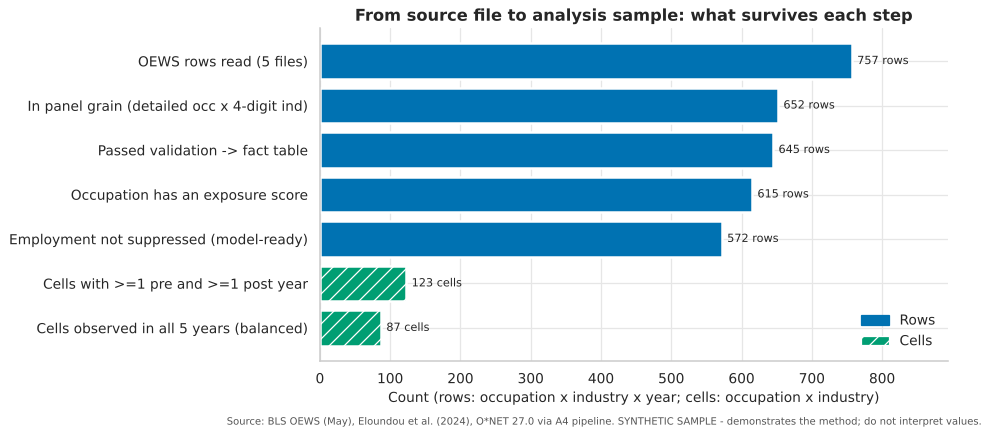

In [4]:
panel = data.load_panel()
print(f"Source: {panel.attrs['source_mode']} | rows: {len(panel):,} | cells: {panel['cell_id'].nunique()} | "
      f"occupations: {panel['soc_code'].nunique()} | industries: {panel['naics_code'].nunique()}")
attrition = data.attrition_table(panel)
display(attrition)
print("Out-of-grain aggregate rows filtered:", attrition.attrs["out_of_grain_filtered"],
      "| quarantined by validation:", attrition.attrs["quarantined"])
plots.plot_attrition(attrition, FIG / "fig10_merge_attrition.png", panel.attrs["source_mode"]);

All checks passed: True


,passed
unique_key,True
years_complete,True
flags_consistent,True
exposure_range,True
positive_values,True
exposure_coverage,True


{'duplicate_keys': 0, 'years': [2021, 2022, 2023, 2024, 2025], 'flag_conflicts': 0, 'emp_null_unflagged': 0, 'exposure_coverage_share': 0.9535, 'occupations_without_exposure': ['47-2061']}


,rows,emp_model_ready,wage_model_ready,emp_suppressed,wage_suppressed,wage_topcoded,employment_covered
year,,,,,,,
2021,129,111,118,13,5,0,305304
2022,130,117,124,8,0,0,345720
2023,128,115,120,9,2,0,314458
2024,129,112,119,12,3,1,333083
2025,129,117,117,6,5,1,366702


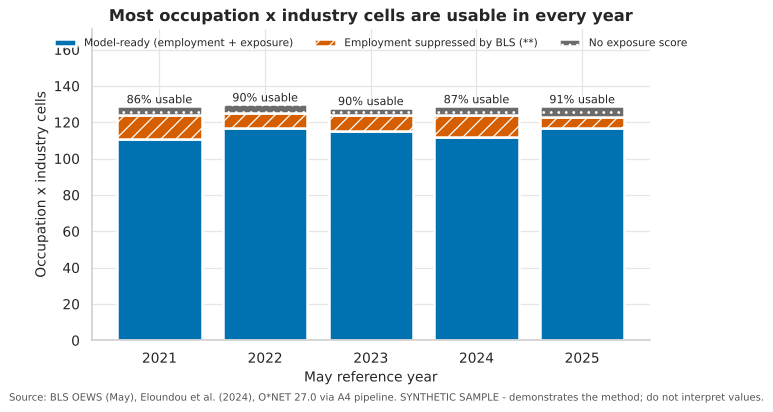

In [5]:
qc = data.validate_panel(panel)
print("All checks passed:", qc.passed)
display(pd.Series(qc.checks, name="passed").to_frame())
print(qc.details)
display(qc.coverage)
plots.plot_coverage(qc.coverage, FIG / "fig01_data_coverage.png", panel.attrs["source_mode"]);

In [6]:
# Reproducible run log: input hashes only, no data. A reviewer compares this against their own licensed rebuild.
display(data.input_manifest()[["source_name", "file_name", "version", "sha256", "rows_read", "source_mode"]])

,source_name,file_name,version,sha256,rows_read,source_mode
0,exposure,eloundou_occ_level_sample.csv,synthetic sample mirroring openai/GPTs-are-GPTs occ_level.csv layout,88491485e46254183fd3e0e4ecc0bd726a88038631fcb0f1a90da06834f226db,25,sample
1,job_zones,onet_job_zones_sample.txt,synthetic sample mirroring O*NET 27.0 Job Zones.txt layout,d89461327eb9b7997d4ea06f54a308e0a4adce84df2d80a778588b1307020816,20,sample
2,oews_2021,oews_nat4d_M2021_sample.csv,OEWS May 2021 national industry-specific,a95e408abd0d45f3b85fbb8740a3cdbdfa779b6cbc5075a644f971d1a8da7ddc,151,sample
3,oews_2022,oews_nat4d_M2022_sample.csv,OEWS May 2022 national industry-specific,689014baac2bfd70866435f1ca28b10c7eb23da7a5a94a2e3280eb32b9cf0ca1,152,sample
4,oews_2023,oews_nat4d_M2023_sample.csv,OEWS May 2023 national industry-specific,e23c3600aacc4cd33dbd5184f009e43cfc53acc129be0d726e8bf727f93db3e9,152,sample
5,oews_2024,oews_nat4d_M2024_sample.csv,OEWS May 2024 national industry-specific,d7bc33a30a659f759d065aa15078606beede38642cd2fd87a4449dec0695ce67,151,sample
6,oews_2025,oews_nat4d_M2025_sample.csv,OEWS May 2025 national industry-specific,435a862f3321d8bde82b735167e5f3d2cd7e74a5623991714496bc280d58749b,151,sample


**Reading.**
* Of 757 OEWS rows read, 105 are BLS aggregate rows outside the panel grain and 7 are quarantined, leaving 645 facts.
* One occupation (Construction Laborers) has no exposure score, leaving 615 rows; employment suppression leaves 572 model-ready rows.
* That yields 123 cells with both a pre and a post observation, and 87 cells observed in all five years.
* All quality checks pass. The 9-14% of cells per year lost to BLS suppression is why trend views use the balanced cells.

## 2. Univariate analysis

In [7]:
display(describe.univariate_summary(panel, ["tot_emp", "log_emp", "a_mean", "log_wage",
                                             "exposure_main", "job_zone_mean", "emp_prse", "mean_prse"]))
occ = describe.occupation_table(panel)
display(occ[["occ_title", "exposure_main", "job_zone_mean", "exposure_group", "exposure_tercile",
             "pre_emp_total", "pre_mean_wage"]])

,n,missing_share,mean,sd,min,p25,median,p75,max,skew,excess_kurtosis
tot_emp,597.0000,0.0740,"2,789.3920","3,801.8818",186.0000,737.0000,"1,324.0000","3,433.0000","30,816.0000",3.5714,16.4566
log_emp,597.0000,0.0740,7.3701,1.0233,5.2257,6.6026,7.1884,8.1412,10.3358,0.3726,-0.3529
a_mean,628.0000,0.0260,"91,029.2516","43,299.7245","32,970.0000","48,325.0000","94,330.0000","116,982.5000","229,540.0000",0.6362,-0.1338
log_wage,628.0000,0.0260,11.3016,0.4937,10.4034,10.7857,11.4546,11.6698,12.3438,-0.0779,-1.2470
exposure_main,615.0000,0.0470,0.6643,0.2361,0.0500,0.5800,0.7400,0.8000,0.9500,-1.3340,1.1234
job_zone_mean,645.0000,0.0000,3.2233,1.1297,1.0000,2.0000,4.0000,4.0000,5.0000,-0.2842,-1.0156
emp_prse,645.0000,0.0000,12.7614,6.6192,1.1000,7.3000,12.4000,18.4000,25.0000,0.0811,-1.1228
mean_prse,645.0000,0.0000,3.3214,1.5613,0.5000,2.0000,3.3000,4.6000,6.0000,-0.0530,-1.1213


,occ_title,exposure_main,job_zone_mean,exposure_group,exposure_tercile,pre_emp_total,pre_mean_wage
soc_code,,,,,,,
43-9021,Data Entry Keyers,0.9500,2.0000,High,High,"11,449.0000","42,441.3333"
15-1252,Software Developers,0.9000,4.0000,High,High,"7,651.5000","145,721.8182"
43-3031,"Bookkeeping, Accounting, and Auditing Clerks",0.9000,3.0000,High,High,"10,950.0000","49,570.8333"
13-2051,Financial and Investment Analysts,0.8400,4.0000,High,High,"12,039.5000","109,049.2857"
13-2041,Credit Analysts,0.8000,4.0000,High,High,"11,742.0000","89,564.0000"
15-2031,Operations Research Analysts,0.7900,5.0000,High,High,"11,706.5000","100,215.0000"
13-2011,Accountants and Auditors,0.7800,4.0000,High,Middle,"30,865.5000","91,361.8750"
23-2011,Paralegals and Legal Assistants,0.7700,3.0000,High,Middle,"8,514.0000","66,310.0000"
43-4051,Customer Service Representatives,0.7400,2.0000,Low,Middle,"30,802.5000","44,503.3333"


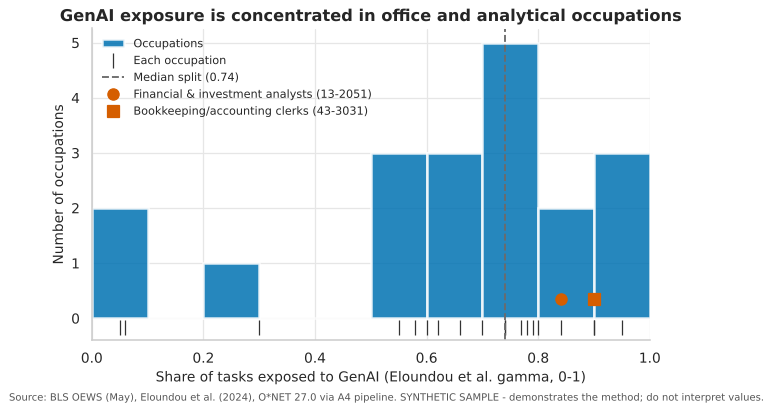

In [8]:
plots.plot_exposure_distribution(occ, panel.attrs["exposure_median"], FIG / "fig02_exposure_distribution.png",
                                 panel.attrs["source_mode"]);

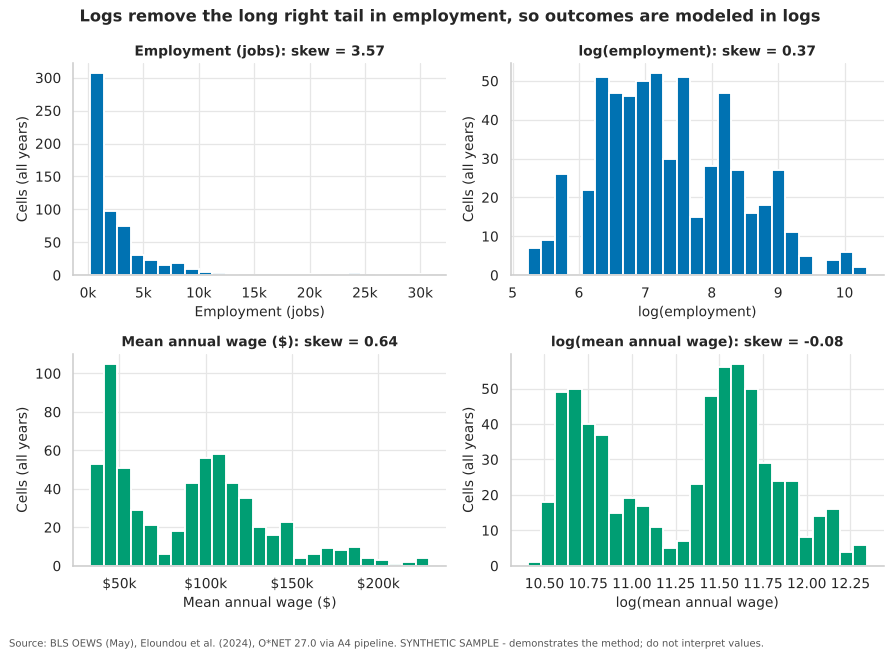

In [9]:
plots.plot_outcome_distributions(panel, FIG / "fig03_outcome_distributions.png", panel.attrs["source_mode"]);

**Reading.**
* Employment is strongly right-skewed (skew ≈ 3.6); its log is near-symmetric (≈ 0.4).
* Wages are bimodal (clerical/service vs. professional occupations); the log removes the remaining skew. Both confirm the A3 choice of log outcomes.
* Exposure is left-skewed in this finance-focused panel. The median occupation (0.74) defines the High/Low split; both focal roles (analysts 0.84, clerks 0.90) are High.
* Relative standard errors exist for every cell, so imprecise cells can be down-weighted in A6 sensitivity checks.

## 3. Bivariate analysis: exposure vs. change after 2022

`cell_changes()` gives each cell's *mean post-period minus mean pre-period* log outcome (pre = 2021-22, post = 2023+). It also gives a **within-industry** version (`_wi`): the cell's change minus its industry's mean change. The `_wi` version is the A3 comparison group, lower-exposure occupations in the same industry over the same period, so industry-wide shocks cancel.

In [10]:
cells = describe.cell_changes(panel)
print("Employment change (approx. %), by exposure group:")
display(describe.group_comparison(cells, "d_log_emp"))
print("Wage change (approx. %), by exposure group:")
display(describe.group_comparison(cells, "d_log_wage"))
print("Exposure vs employment change:", describe.correlation_with_pvalues(cells, "exposure_main", "d_log_emp"))
print("Exposure vs wage change:      ", describe.correlation_with_pvalues(cells, "exposure_main", "d_log_wage"))

Employment change (approx. %), by exposure group:


,n,mean,median,sd,approx_pct_change
exposure_group,,,,,
High,53,0.0265,0.0287,0.0297,2.6825
Low,70,0.0546,0.0536,0.0406,5.6140


Wage change (approx. %), by exposure group:


,n,mean,median,sd,approx_pct_change
exposure_group,,,,,
High,53,0.0815,0.0788,0.0386,8.4894
Low,71,0.0819,0.0858,0.0417,8.5390


Exposure vs employment change: {'n': 123, 'pearson_r': -0.6143511663187667, 'pearson_p': 4.112316686780053e-14, 'spearman_rho': -0.5189894333215862, 'spearman_p': 7.758914002063475e-10}
Exposure vs wage change:       {'n': 124, 'pearson_r': -0.0067679414037843085, 'pearson_p': 0.9405312360414957, 'spearman_rho': -0.009538792998339353, 'spearman_p': 0.9162598566143001}


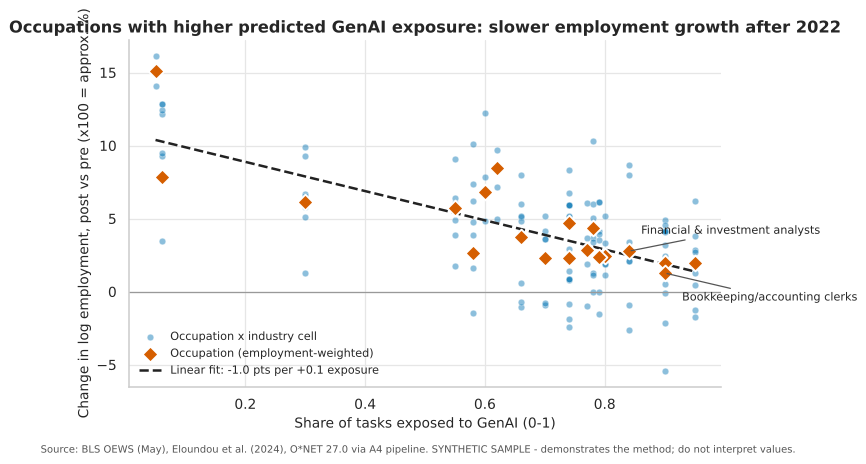

In [11]:
occ_emp = describe.occupation_changes(cells, "d_log_emp")
plots.plot_exposure_vs_change(cells, occ_emp, "d_log_emp", FIG / "fig04_exposure_vs_emp_change.png",
                              panel.attrs["source_mode"]);

group,High,Low,Middle
year,,,
2021,99.5213,98.7584,97.4600
2022,100.0000,100.0000,100.0000
2023,102.4986,103.2663,100.9787
2024,101.9584,107.0930,101.8727
2025,102.3052,111.6434,103.1380


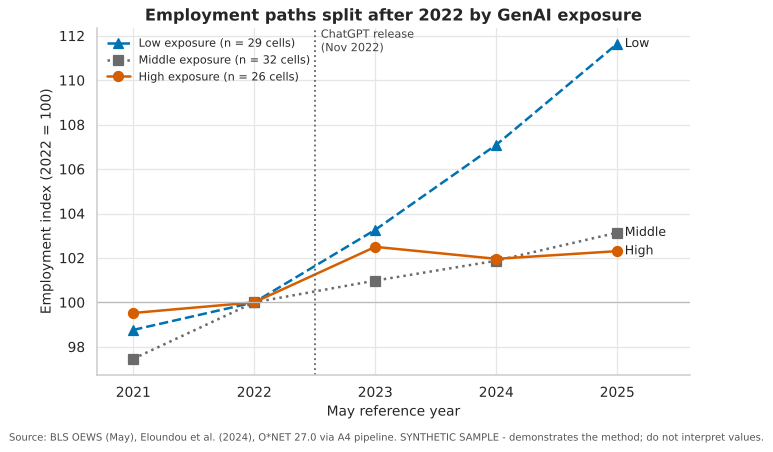

In [12]:
balanced = data.balanced_cells(panel, "log_emp")
trend = describe.trend_index(balanced, "exposure_tercile", "log_emp")
display(trend.pivot(index="year", columns="group", values="index"))
plots.plot_trend_index(trend, "Employment", FIG / "fig05_emp_trend_by_exposure.png", panel.attrs["source_mode"]);

**Reading.**
* Employment in high-exposure cells grew about +2.7% from the pre to the post period, against about +5.6% in low-exposure cells. The scatter slopes down: roughly 1 point less growth per +0.1 exposure.
* The balanced-panel index shows the terciles moving roughly together through 2022 and separating afterwards.
* Wage changes are unrelated to exposure (r ≈ 0).

## 4. Multivariate analysis

(a) How do exposure, preparation, pay and size relate to each other? (b) Does the exposure-employment association survive controls for preparation, pre-period pay and industry? Standard errors are clustered by occupation (CR1, G − 1 df), because exposure varies only across occupations.

,exposure_main,job_zone_mean,pre_log_wage,pre_log_emp,d_log_emp,d_log_wage
exposure_main,1.0000,0.1688,-0.0688,-0.0424,-0.5190,-0.0095
job_zone_mean,0.1688,1.0000,0.8085,-0.0818,-0.2737,0.1357
pre_log_wage,-0.0688,0.8085,1.0000,-0.1322,-0.1541,0.0208
pre_log_emp,-0.0424,-0.0818,-0.1322,1.0000,0.0195,0.0269
d_log_emp,-0.5190,-0.2737,-0.1541,0.0195,1.0000,0.0264
d_log_wage,-0.0095,0.1357,0.0208,0.0269,0.0264,1.0000


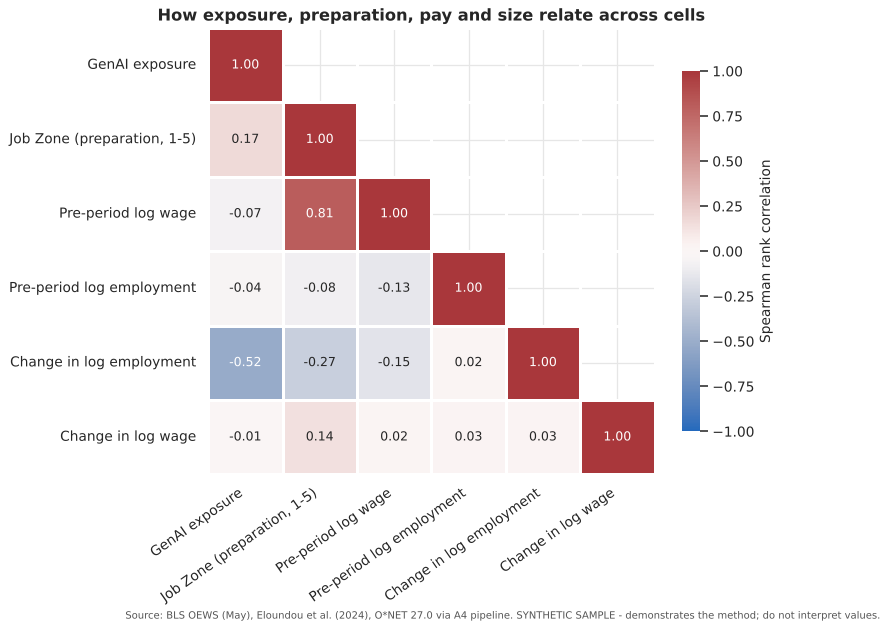

In [13]:
corr_cols = ["exposure_main", "job_zone_mean", "pre_log_wage", "pre_log_emp", "d_log_emp", "d_log_wage"]
corr = describe.correlation_table(cells, corr_cols)
display(corr)
plots.plot_correlation_heatmap(corr, report.LABELS, FIG / "fig06_correlation_heatmap.png", panel.attrs["source_mode"]);

Multicollinearity check (VIF; < 5 acceptable):


,VIF
exposure_z,1.3889
job_zone_mean,4.3814
pre_log_wage,3.7964



d_log_emp ~ exposure_z + job_zone_mean + pre_log_wage | FE: naics_code   n = 123, occupation clusters = 19, R² = 0.453


,coef,se_cluster,t,p_value,ci_low,ci_high
const,0.2095,0.1312,1.5969,0.1277,-0.0661,0.4852
exposure_z,-0.0258,0.0039,-6.5917,0.0000,-0.0341,-0.0176
job_zone_mean,0.0046,0.0050,0.9087,0.3755,-0.0060,0.0151
pre_log_wage,-0.0149,0.0131,-1.1369,0.2705,-0.0425,0.0127



d_log_wage ~ exposure_z + job_zone_mean + pre_log_wage | FE: naics_code   n = 124, occupation clusters = 19, R² = 0.106


,coef,se_cluster,t,p_value,ci_low,ci_high
const,0.2496,0.1053,2.3702,0.0292,0.0284,0.4708
exposure_z,-0.0042,0.0030,-1.3977,0.1792,-0.0105,0.0021
job_zone_mean,0.0122,0.0051,2.3775,0.0287,0.0014,0.0230
pre_log_wage,-0.0177,0.0106,-1.6715,0.1119,-0.0400,0.0045


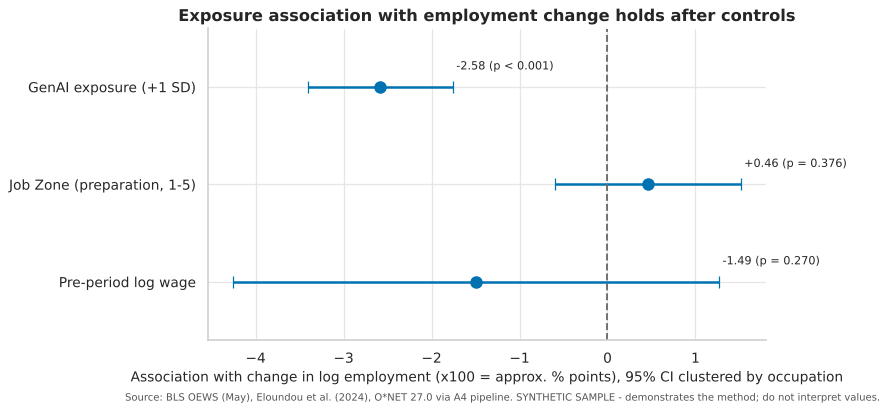

In [14]:
X = ["exposure_z", "job_zone_mean", "pre_log_wage"]
print("Multicollinearity check (VIF; < 5 acceptable):")
display(inference.vif(cells, X).to_frame())
m_emp = inference.ols_cluster(cells, "d_log_emp", X, fixed_effects=["naics_code"])
m_wage = inference.ols_cluster(cells, "d_log_wage", X, fixed_effects=["naics_code"])
for m in (m_emp, m_wage):
    print(f"\n{m.formula}   n = {m.n_obs}, occupation clusters = {m.n_clusters}, R² = {m.r2:.3f}")
    display(m.table)
plots.plot_coefficients(m_emp.table, report.LABELS, path=FIG / "fig07_model_coefficients.png",
                        source_mode=panel.attrs["source_mode"]);

**Reading.**
* Job Zone and pre-period wage are strongly correlated with each other (ρ ≈ 0.8, VIF ≈ 4), but neither is strongly correlated with exposure (|ρ| ≤ 0.17). Exposure is therefore not a proxy for skill or pay.
* With industry fixed effects and those controls, one standard deviation more exposure is **associated** with about 2.6 points less employment growth. The occupation-clustered 95% CI is −3.4 to −1.8.
* In the wage model exposure shows no association (CI spans 0); Job Zone is the only wage predictor.

## 5. Hypothesis tests

A gap is treated as **practically meaningful** only if it is at least 1 percentage point of growth over the post period (`report.PRACTICAL_THRESHOLD`). Each test's occupation-cluster CI is classified against that band, so "not significant" is never read as "no effect".

### 5.1 Employment: A3 H1 (primary, within industry)

* **H₀:** μ_High − μ_Low ≥ 0. Relative to their industry, high-exposure cells' employment grew at least as fast as low-exposure cells' after 2022.
* **H₁:** μ_High − μ_Low < 0. It grew more slowly.
* **α = 0.05.** Unit: occupation × industry cell; outcome: within-industry change in log employment (`d_log_emp_wi`).

**Assumptions checked.**
* Normality within each group: Shapiro-Wilk plus Q-Q plots.
* Equal variances: Levene, median-centred. The result picks Student's t or Welch's t.
* Independence is the weak point: cells of one occupation share one exposure score. The test is therefore paired with an occupation-cluster bootstrap CI and an occupation-level permutation test (n = occupations).
* Mann-Whitney U is reported as a distribution-free check.

,assumption checks
n_a,53
n_b,70
shapiro_a_W,0.9781
shapiro_a_p,0.4362
shapiro_b_W,0.9782
shapiro_b_p,0.2597
levene_W,3.9743
levene_p,0.0484
normal_or_large_n,True
equal_variances,False


Welch's t: t = -4.568, p = 5.99e-06  ->  Reject H0
Hedges' g = -0.79;  Mann-Whitney p = 1.14e-05
Occupation-cluster 95% CI for the gap (pp): [-4.43, -1.27]  ->  practically meaningful
Occupation-level permutation test: {'n_occupations': 19, 'spearman_rho': -0.7945569348515471, 'p_value': 9.999000099990002e-05, 'alternative': 'less', 'n_permutations': 10000}

High-exposure cells' employment grew about 2.7% less than low-exposure cells' between the pre and post periods (Hedges' g = -0.79). The gap is statistically distinguishable from zero at the 5% level, and the occupation-cluster bootstrap CI also excludes zero, so the result does not rest on treating cells of the same occupation as independent. Against a minimum meaningful gap of 1.0 percentage point(s), the cluster CI [-4.43, -1.27] is: practically meaningful. This is a differential association between predicted task exposure and the outcome, not an effect of GenAI adoption.


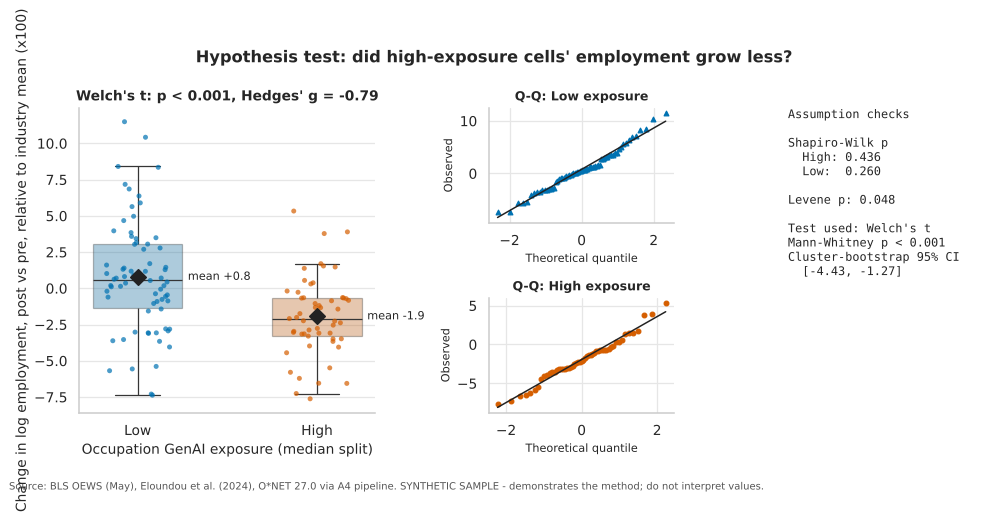

In [15]:
t_emp = inference.exposure_group_test(cells, "d_log_emp_wi", alternative="less",
                                     practical_threshold=report.PRACTICAL_THRESHOLD)
display(pd.Series(t_emp.assumptions, name="assumption checks").to_frame())
print(f"{t_emp.test_used}: t = {t_emp.statistic:.3f}, p = {t_emp.p_value:.2e}  ->  {t_emp.decision}")
print(f"Hedges' g = {t_emp.hedges_g:.2f};  Mann-Whitney p = {t_emp.mann_whitney_p:.2e}")
print(f"Occupation-cluster 95% CI for the gap (pp): [{t_emp.cluster_ci_low*100:.2f}, {t_emp.cluster_ci_high*100:.2f}]"
      f"  ->  {t_emp.practical_verdict}")
print("Occupation-level permutation test:", inference.occupation_permutation_test(occ_emp, alternative="less"))
print()
print(t_emp.interpretation)
plots.plot_group_test(cells, "d_log_emp_wi", t_emp, FIG / "fig08_hypothesis_test_emp.png", panel.attrs["source_mode"]);

**Interpretation.**
* Both groups pass Shapiro-Wilk (p > 0.25) and the Q-Q plots are straight, so normality holds. Levene rejects equal variances narrowly (p ≈ 0.048), so the function selects **Welch's t**.
* We **reject H₀**. Relative to their industries, high-exposure cells' employment grew about 2.7 points less than low-exposure cells' (g ≈ −0.8, medium-to-large).
* The result does not rest on treating cells as independent: the occupation-cluster CI (−4.4 to −1.3 pp) excludes zero, and the 19-occupation permutation test agrees.
* The whole CI lies beyond the 1-point band, so the gap is **practically meaningful**, not just detectable.
* It remains a differential association between predicted exposure and employment, not a measured impact of GenAI adoption.

### 5.2 Wages (two-sided, within industry)

* **H₀:** μ_High − μ_Low = 0 for the within-industry change in log mean wage. **H₁:** ≠ 0.

In [16]:
t_wage = inference.exposure_group_test(cells, "d_log_wage_wi", alternative="two-sided",
                                      practical_threshold=report.PRACTICAL_THRESHOLD)
print(f"{t_wage.test_used}: p = {t_wage.p_value:.3f}, g = {t_wage.hedges_g:.2f}, cluster CI (pp) "
      f"[{t_wage.cluster_ci_low*100:.2f}, {t_wage.cluster_ci_high*100:.2f}] -> {t_wage.decision}; {t_wage.practical_verdict}")
print(t_wage.interpretation)

Student's t: p = 0.974, g = 0.01, cluster CI (pp) [-1.16, 1.00] -> Fail to reject H0; inconclusive
High- and low-exposure cells' mean wages changed by virtually the same amount between the pre and post periods (gap +0.02%, Hedges' g = 0.01). The gap is not statistically distinguishable from zero at the 5% level (the occupation-cluster bootstrap CI also includes zero). Against a minimum meaningful gap of 1.0 percentage point(s), the cluster CI [-1.16, +1.00] is: inconclusive. This is a differential association between predicted task exposure and the outcome, not an effect of GenAI adoption.


**Interpretation.**
* We **fail to reject H₀**: no wage difference is detected (g ≈ 0).
* The CI (about −1.2 to +1.0 pp) still reaches past the 1-point band on both sides, so the verdict is **inconclusive**, not "no wage effect": a small but meaningful pay gap cannot be ruled out.
* Mean wage is the pay of incumbents, so a cell that loses jobs can show a wage change purely from who remains. Employment and wages stay separate outcomes.

### 5.3 Timing: event-time gaps, panel pooling, delayed post, NAICS change

Each May estimate pools six survey panels from three years. Only 1 of 6 panels in May 2023 post-dates ChatGPT, 3 of 6 in May 2024 and 5 of 6 in May 2025. Any real change therefore appears gradually in OEWS even if it happened all at once.

,year,gap,ci_low,ci_high,n_high,n_low,post_chatgpt_panels
0,2021,0.0050,-0.0091,0.0206,46,59,0
1,2022,0.0000,0.0000,0.0000,51,66,0
2,2023,0.0007,-0.0146,0.0155,46,63,1
3,2024,-0.0239,-0.0427,-0.0068,44,62,3
4,2025,-0.0532,-0.0788,-0.0300,50,60,5


Delayed post (2024+)               gap -3.90%, p = 3.5e-09, cluster CI (pp) [-5.76, -2.27] -> Reject H0; practically meaningful
Excluding May 2021 (2017 NAICS)    gap -2.52%, p = 5.5e-04, cluster CI (pp) [-4.45, -0.97] -> Reject H0; detectable, size uncertain


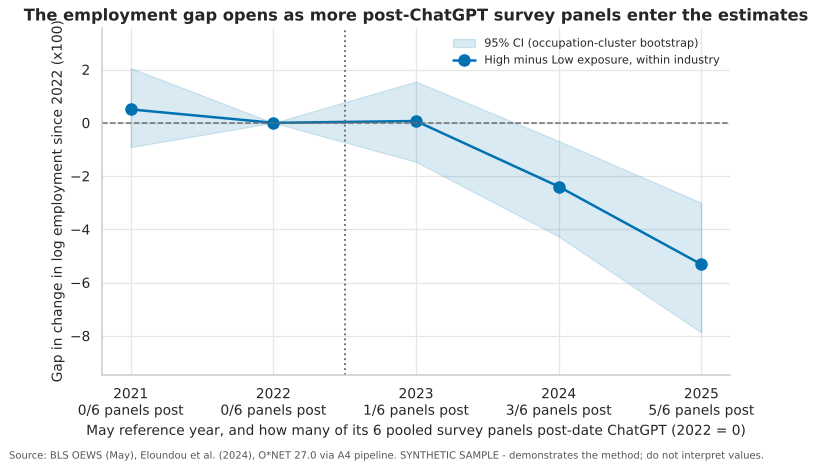

In [17]:
gaps = inference.event_time_gaps(describe.cell_year_changes(panel, "log_emp"))
display(gaps.merge(data.oews_vintage()[["post_chatgpt_panels"]], left_on="year", right_index=True))
plots.plot_event_time_gaps(gaps, data.oews_vintage(), FIG / "fig11_event_time_gaps_emp.png", panel.attrs["source_mode"])

kw = {"alternative": "less", "practical_threshold": report.PRACTICAL_THRESHOLD}
t_del = inference.exposure_group_test(describe.cell_changes(panel, post_col="post_delayed"), "d_log_emp_wi", **kw)
t_no21 = inference.exposure_group_test(describe.cell_changes(panel[panel["year"] != 2021]), "d_log_emp_wi", **kw)
for name, t in (("Delayed post (2024+)", t_del), ("Excluding May 2021 (2017 NAICS)", t_no21)):
    print(f"{name:34s} gap {t.diff_pct_points:+.2f}%, p = {t.p_value:.1e}, cluster CI (pp) "
          f"[{t.cluster_ci_low*100:.2f}, {t.cluster_ci_high*100:.2f}] -> {t.decision}; {t.practical_verdict}")

**Interpretation.**
* The gap is about 0 in 2023 (1/6 post panels), −2.4 pp in 2024 (3/6) and −5.3 pp in 2025 (5/6), and the delayed-post test gives a larger gap (≈ −3.9 pp). This matches the share of post-ChatGPT survey data, so the build-up is **not by itself evidence of gradual adoption**; pooling alone would produce it. A6 will use event-time coefficients and a panel-share timing variable rather than a single post dummy.
* Dropping May 2021 (the only 2017-NAICS release) keeps a significant gap (≈ −2.5 pp), but its CI now reaches inside the 1-point band (*detectable, size uncertain*). The NAICS change is a sensitivity to carry into A6.

### 5.4 Placebo: 2021 → 2022 (both pre-ChatGPT)

* **H₀:** no exposure gap in the within-industry 2021 → 2022 employment change. **H₁:** a gap exists. Two-sided.
* A real gap here would mean exposure groups were already diverging before ChatGPT, which would undercut the comparison.

In [18]:
pre = describe.pre_period_change(panel, "log_emp").merge(cells[["cell_id"]], on="cell_id")
t_pl = inference.exposure_group_test(pre, "d_pre_log_emp", alternative="two-sided",
                                    practical_threshold=report.PRACTICAL_THRESHOLD)
print(f"Placebo: gap {t_pl.diff_pct_points:+.2f}%, p = {t_pl.p_value:.2f}, cluster CI (pp) "
      f"[{t_pl.cluster_ci_low*100:.2f}, {t_pl.cluster_ci_high*100:.2f}] -> {t_pl.decision}; {t_pl.practical_verdict}")

Placebo: gap -0.50%, p = 0.50, cluster CI (pp) [-2.06, 0.91] -> Fail to reject H0; inconclusive


**Interpretation.**
* No pre-period gap is detected (−0.5 pp, p ≈ 0.50). Parallel pre-trends are therefore *not contradicted*.
* With two pre years the CI (−2.1 to +0.9 pp) is wide, so they are *not established* either.
* A causal reading would further need:
  * no concurrent occupation-specific shock correlated with exposure;
  * actual adoption that rises with predicted exposure;
  * no spillovers onto low-exposure occupations;
  * stable cell composition.

  None of these can be checked with these fields (`docs/A5_RESEARCH_DESIGN.md` §5).

## 6. Finance contrast (descriptive only, per A3 feedback)

Financial & investment analysts (13-2051) vs. bookkeeping, accounting & auditing clerks (43-3031), each on its industry cells observed in every year, indexed to 2022 = 100.

,focal_role,year,total_emp,mean_wage,n_industries,emp_index,wage_index
0,analyst,2021,"9,700.0000","109,016.6667",3,100.4557,98.4379
1,analyst,2022,"9,656.0000","110,746.6667",3,100.0000,100.0000
2,analyst,2023,"9,645.0000","117,540.0000",3,99.8861,106.1341
3,analyst,2024,"9,892.0000","117,433.3333",3,102.4441,106.0378
4,analyst,2025,"10,121.0000","126,833.3333",3,104.8157,114.5256
5,clerk_contrast,2021,"1,802.0000","55,705.0000",2,101.6930,105.1236
6,clerk_contrast,2022,"1,772.0000","52,990.0000",2,100.0000,100.0000
7,clerk_contrast,2023,"1,861.0000","57,035.0000",2,105.0226,107.6335
8,clerk_contrast,2024,"1,853.0000","60,165.0000",2,104.5711,113.5403
9,clerk_contrast,2025,"1,902.0000","62,160.0000",2,107.3363,117.3052


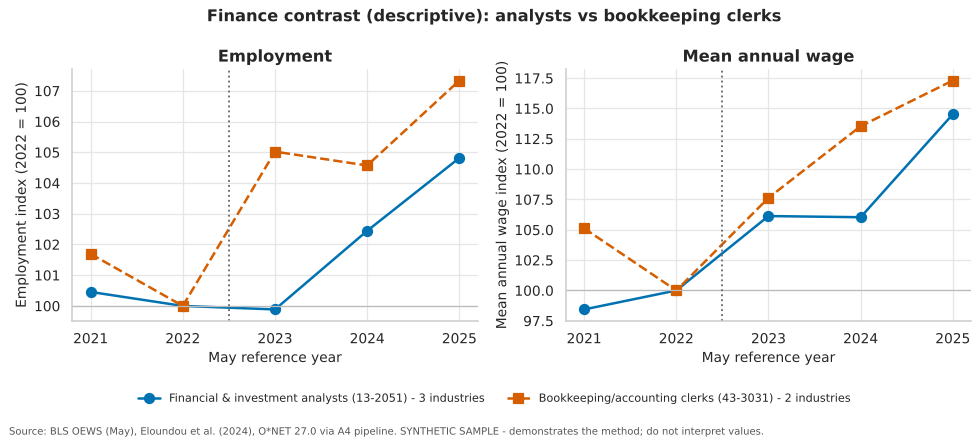

In [19]:
contrast = describe.focal_contrast(panel)
display(contrast)
plots.plot_focal_contrast(contrast, FIG / "fig09_analyst_vs_clerk.png", panel.attrs["source_mode"]);

**Reading.**
* Both roles grow after 2022 in the sample, and both sit at the high-exposure end of the Section 3 slope.
* With 2-3 industries per role this is context, not a test. Whether GenAI complements analysts' tasks while substituting for clerks' cannot be answered with these fields. The A6 analyst-by-post interaction will quantify the contrast; here it stays descriptive.

## 7. Findings, business implications, and implications for modeling

| # | Finding (sample run; known-answer test) | Business implication (if the real data agree) | Implication for A6 |
|---|---|---|---|
| 1 | Within industry, employment in high-exposure cells grew ~2.7 pp less; practically meaningful (CI beyond ±1 pp); survives controls, clustering and nonparametric checks | Plan a slower-headcount-growth scenario for exposed roles alongside the baseline | Expect negative β on employment; keep occupation-clustered SEs and industry-by-year FE |
| 2 | Gap appears as post-ChatGPT survey panels accumulate (0 → −2.4 → −5.3 pp) | Early OEWS releases understate any change; revisit with each release | Event-time coefficients and a panel-share timing variable, not a single post dummy |
| 3 | No detectable wage gap, but ±1 pp not ruled out | No GenAI pay discount is justified; keep monitoring | Wage stays two-sided; report CIs against the 1-pp band |
| 4 | Placebo 2021 → 2022 shows no gap (wide CI) | The high-vs-low comparison is credible but not proven | Formal pre-period coefficients; note only two pre years |
| 5 | Exposure is nearly uncorrelated with preparation and pay | Exposure is a separate planning dimension from skill or pay band | Job Zone as moderator, not confounder; VIFs < 5 |
| 6 | 9-14% of cells per year suppressed; excluding May 2021 weakens the size estimate | Small occupation-industry groups are under-represented | Balanced vs unbalanced estimates; PRSE weighting; NAICS sensitivity |

**Not supported by these fields:** GenAI adoption or use; causal displacement or augmentation; hires vs separations (employment is a level); individual worker outcomes; hours or total compensation; firm or regional patterns. The non-technical version is `docs/A5_EXECUTIVE_SUMMARY.md`.

## 8. Regenerate every output and the run log in one call

`report.run_all()` re-runs everything above and writes figures (`reports/figures/`), tables, the JSON summary and the checksum run log (`reports/eda/`). The same entry point is `uv run oews-eda`, and `uv run oews-eda --verify-against reports/eda/eda_run_log.json` checks a rebuilt database's inputs against the log.

In [20]:
summary = report.run_all()
print("Figures:", sorted(p.name for p in FIG.glob("fig*.png")))
display(pd.read_csv(data.REPO_ROOT / "reports" / "eda" / "hypothesis_tests.csv", index_col=0)
        [["test", "p", "gap_pct", "cluster_ci_low_pct", "cluster_ci_high_pct", "decision", "practical_verdict"]])
print("Data:", summary["source_mode"])

Figures: ['fig01_data_coverage.png', 'fig02_exposure_distribution.png', 'fig03_outcome_distributions.png', 'fig04_exposure_vs_emp_change.png', 'fig05_emp_trend_by_exposure.png', 'fig06_correlation_heatmap.png', 'fig07_model_coefficients.png', 'fig08_hypothesis_test_emp.png', 'fig09_analyst_vs_clerk.png', 'fig10_merge_attrition.png', 'fig11_event_time_gaps_emp.png']


,test,p,gap_pct,cluster_ci_low_pct,cluster_ci_high_pct,decision,practical_verdict
primary_emp_within_industry,Welch's t,0.0000,-2.6922,-4.4292,-1.2721,Reject H0,practically meaningful
emp_raw_change,Student's t,0.0000,-2.7757,-4.6896,-1.2224,Reject H0,practically meaningful
wage_within_industry,Student's t,0.9737,0.0233,-1.1640,0.9968,Fail to reject H0,inconclusive
emp_delayed_post,Student's t,0.0000,-3.8965,-5.7557,-2.2706,Reject H0,practically meaningful
emp_excluding_2021,Student's t,0.0005,-2.5182,-4.4521,-0.9676,Reject H0,"detectable, size uncertain"
placebo_2021_2022,Student's t,0.5038,-0.5029,-2.0608,0.9132,Fail to reject H0,inconclusive


Data: sample
